# M5 demand forecasting walkthrough: CA_1 FOODS

This notebook reads the outputs of the pipeline (`python -m src.backtest`, `python -m src.inventory`) and walks through the data, the backtest and the inventory policy. It does not retrain anything, so it runs in seconds.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src.data import load_panel
from src.metrics import summarize, weekly, wape
from src.backtest import MODELS, CUTOFFS, OUT
pd.set_option('display.float_format', '{:.3f}'.format)
panel = load_panel()
fc = pd.read_parquet(OUT / 'forecasts.parquet')
sim = pd.read_csv(OUT / 'inventory_simulation.csv')

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The data

One Walmart store in California, the FOODS category: three departments, roughly 1,400 items, daily unit sales from 2011 to May 2016, weekly shelf prices, and a calendar with holidays and SNAP (food-stamp) days.

dept_id
FOODS_1    216
FOODS_2    398
FOODS_3    823
Name: id, dtype: int64
share of item-days with zero sales: 46.8%


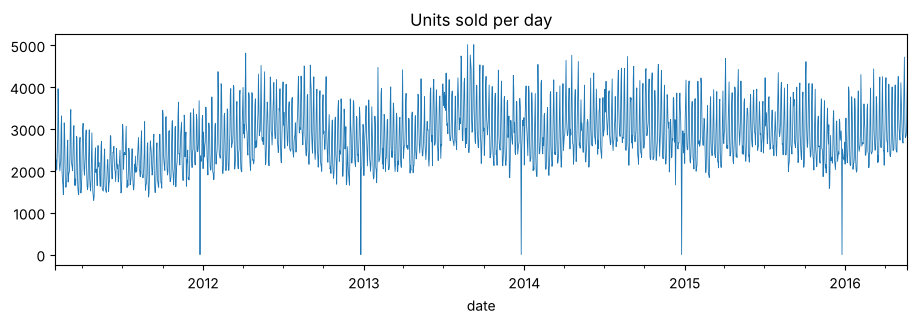

In [2]:
print(panel.groupby('dept_id', observed=True)['id'].nunique())
print(f"share of item-days with zero sales: {(panel.sales == 0).mean():.1%}")
daily = panel[panel.d <= 1941].groupby('date')['sales'].sum()
daily.plot(figsize=(11, 3), lw=0.6, title='Units sold per day'); plt.show()

Demand is **intermittent**: almost half of all item-days have zero sales. That is typical of a dark store's long tail too, and it is why we use WAPE rather than MAPE (MAPE divides by zero).

In [3]:
by_wday = panel[panel.d > 1941 - 365].groupby(['wday'])['sales'].mean()
by_wday.index = ['Sat', 'Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri']
snap = panel[panel.d > 1941 - 365].groupby('snap')['sales'].mean()
print('Mean units per item-day by weekday:'); print(by_wday.round(2))
print(f'SNAP-day uplift: {snap[1] / snap[0] - 1:.1%}')

Mean units per item-day by weekday:
Sat   2.490
Sun   2.620
Mon   1.980
Tue   1.750
Wed   1.710
Thu   1.700
Fri   1.960
Name: sales, dtype: float32
SNAP-day uplift: 7.8%


## 2. Backtest results

Five rolling origins, each forecasting the next 28 days. WAPE = sum of absolute errors / sum of actual units.

In [4]:
summarize(fc, MODELS).T

,all
SeasonalNaive_wape,0.804
SeasonalNaive_bias,-0.057
MA28_wape,0.691
MA28_bias,-0.051
AutoETS_wape,0.677
AutoETS_bias,-0.047
LightGBM_wape,0.663
LightGBM_bias,-0.068


In [5]:
summarize(fc, MODELS, by=['cutoff'])[[f'{m}_wape' for m in MODELS]]

,SeasonalNaive_wape,MA28_wape,AutoETS_wape,LightGBM_wape
cutoff,,,,
1801,0.841,0.730,0.702,0.680
1829,0.792,0.686,0.685,0.680
1857,0.790,0.692,0.668,0.665
1885,0.824,0.682,0.684,0.658
1913,0.777,0.671,0.648,0.636


Item-week WAPE is the more relevant number for replenishment: errors on individual days partly cancel within a week.

In [6]:
summarize(weekly(fc, MODELS), MODELS).T

,all
SeasonalNaive_wape,0.408
SeasonalNaive_bias,-0.057
MA28_wape,0.372
MA28_bias,-0.051
AutoETS_wape,0.389
AutoETS_bias,-0.047
LightGBM_wape,0.367
LightGBM_bias,-0.068


In [7]:
summarize(fc, MODELS, by=['dept_id'])[[f'{m}_wape' for m in MODELS]]

,SeasonalNaive_wape,MA28_wape,AutoETS_wape,LightGBM_wape
dept_id,,,,
FOODS_1,1.029,0.869,0.869,0.856
FOODS_2,0.951,0.809,0.799,0.780
FOODS_3,0.733,0.635,0.617,0.605


### Where does LightGBM win?
Split items into volume tiers and compare WAPE per tier.

In [8]:
vol = fc.groupby('id')['y'].mean()
fc['tier'] = fc['id'].map(pd.qcut(vol, [0, .5, .8, .95, 1], labels=['slow 50%', 'mid 30%', 'fast 15%', 'top 5%']))
summarize(fc, MODELS, by=['tier'])[[f'{m}_wape' for m in MODELS]]

,SeasonalNaive_wape,MA28_wape,AutoETS_wape,LightGBM_wape
tier,,,,
slow 50%,1.300,1.151,1.146,1.162
mid 30%,0.997,0.827,0.807,0.800
fast 15%,0.751,0.632,0.614,0.598
top 5%,0.490,0.441,0.429,0.400


### WAPE by days ahead
The week-1 model can use last week's sales; the week-4 model cannot.

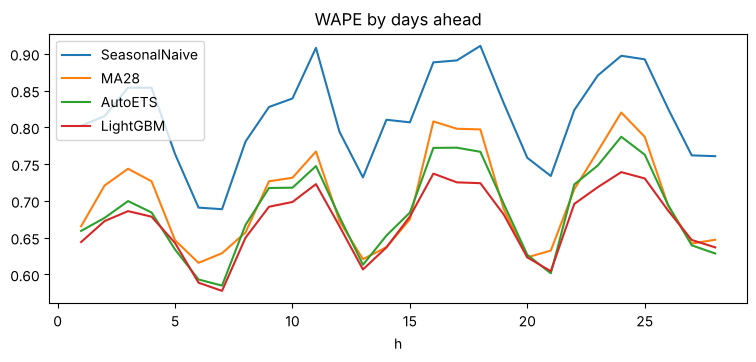

In [9]:
fc['h'] = fc['d'] - fc['cutoff']
h = fc.groupby('h').apply(lambda g: pd.Series({m: wape(g.y, g[m]) for m in MODELS}), include_groups=False)
h.plot(figsize=(9, 3.5), title='WAPE by days ahead'); plt.show()

In [10]:
imp = pd.read_csv(OUT / 'feature_importance.csv').groupby('feature')['gain'].mean()
(imp / imp.sum()).sort_values(ascending=False).head(15)

feature
rmean_56         0.177
rmean_14         0.154
item_id          0.150
rmean_28         0.143
rmean_112        0.127
rmean_7          0.077
wday_mean_4      0.067
lag_364          0.009
age              0.009
event_name_1     0.008
rstd_28          0.008
week_of_year     0.007
wday             0.007
lag_w0           0.007
price_rel_mean   0.005
Name: gain, dtype: float64

## 3. From forecast to reorder rule

Daily review, 2-day lead time, lost sales. Order-up-to level S = forecast over the next 3 days + z × σ₃, where σ₃ is each item's out-of-sample error over 3 days, measured on backtest folds 1 to 4. The policy is then simulated on fold 5, which none of the σ estimates saw.

In [11]:
sim.pivot_table(index='policy', columns='model', values='fill_rate')

model,AutoETS,LightGBM,MA28,SeasonalNaive
policy,,,,
ABC (98/95/90%),0.966,0.965,0.961,0.970
z=0.00,0.844,0.845,0.828,0.812
z=0.50,0.909,0.909,0.899,0.910
z=0.84,0.934,0.934,0.927,0.938
z=1.28,0.955,0.954,0.949,0.960
z=1.65,0.965,0.965,0.961,0.970
z=2.05,0.973,0.972,0.970,0.977
z=2.33,0.977,0.976,0.975,0.981


In [12]:
sim.pivot_table(index='policy', columns='model', values='avg_stock_value').round(0)

model,AutoETS,LightGBM,MA28,SeasonalNaive
policy,,,,
ABC (98/95/90%),37748.000,35708.000,36715.000,43723.000
z=0.00,12217.000,11678.000,11790.000,13317.000
z=0.50,18357.000,17496.000,17732.000,21373.000
z=0.84,22907.000,21801.000,22032.000,26467.000
z=1.28,29029.000,27581.000,27999.000,33576.000
z=1.65,34260.000,32537.000,33212.000,39684.000
z=2.05,40025.000,37948.000,38947.000,46446.000
z=2.33,44090.000,41746.000,43029.000,51226.000


In [13]:
pol = pd.read_csv(OUT / 'reorder_policy.csv')
pol[pol.model == 'LightGBM'].sort_values('fcst_daily', ascending=False).head(10)

,id,model,abc,fcst_daily,sigma_P,z,safety_stock,reorder_point,order_up_to,fill_rate
4908,FOODS_3_090_CA_1,LightGBM,A,48.147,52.161,2.054,107.126,193.063,236.788,1.000
4937,FOODS_3_120_CA_1,LightGBM,A,40.345,68.981,2.054,141.669,197.320,233.971,1.000
5389,FOODS_3_586_CA_1,LightGBM,A,39.579,19.520,2.054,40.090,99.715,126.428,1.000
5066,FOODS_3_252_CA_1,LightGBM,A,36.663,20.180,2.054,41.446,96.554,123.120,1.000
4882,FOODS_3_064_CA_1,LightGBM,A,28.450,14.800,2.054,30.395,78.889,103.869,1.000
5094,FOODS_3_282_CA_1,LightGBM,A,24.694,25.116,2.054,51.582,93.245,108.414,1.000
5390,FOODS_3_587_CA_1,LightGBM,A,23.388,29.226,2.054,60.022,104.837,124.887,1.000
5307,FOODS_3_501_CA_1,LightGBM,A,22.217,29.779,2.054,61.159,104.527,121.786,1.000
5107,FOODS_3_295_CA_1,LightGBM,A,21.193,23.360,2.054,47.976,86.889,104.430,1.000
4624,FOODS_2_197_CA_1,LightGBM,A,18.537,11.427,2.054,23.469,56.036,70.561,1.000
